# 3 · Themes: clustering on relatedness

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
DATA = ROOT / "data" / "processed"
SEED = "Hundred Years' War"
BLUE, GRAY = "#2a78d6", "#b9b8b1"
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})

> ✏️ **[Your text]** How were the themes found? (Each article joined to its 10 most related; Louvain communities on that graph.) Who named them?

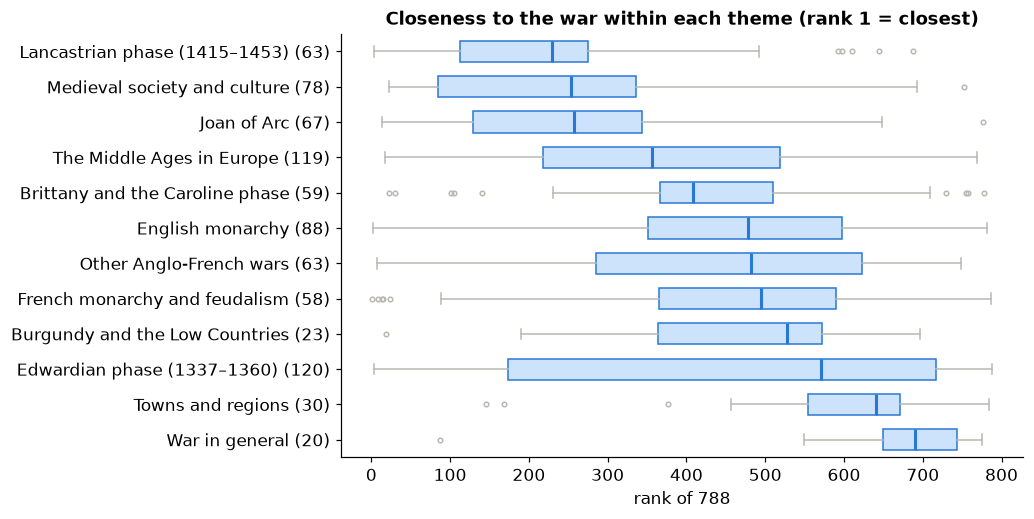

In [2]:
clusters = pd.read_parquet(DATA / "clusters.parquet").set_index("title")
seed = pd.read_parquet(DATA / "seed_similarity.parquet").set_index("title")
themes = clusters.join(seed["milne_witten_rank"])
order = themes.groupby("cluster_name")["milne_witten_rank"].median().sort_values().index

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([themes.loc[themes.cluster_name == t, "milne_witten_rank"] for t in order][::-1],
           orientation="horizontal", widths=0.6, patch_artist=True, boxprops={"facecolor": "#cde2fb", "color": BLUE},
           medianprops={"color": BLUE, "linewidth": 2}, whiskerprops={"color": GRAY}, capprops={"color": GRAY},
           flierprops={"markersize": 3, "markeredgecolor": GRAY})
ax.set_yticks(range(1, len(order) + 1), [f"{t} ({(themes.cluster_name == t).sum()})" for t in order][::-1])
ax.set_title("Closeness to the war within each theme (rank 1 = closest)")
ax.set_xlabel("rank of 788");

> ✏️ **[Your text]** Which themes sit closest to the war, which farthest, and does that surprise you?

In [3]:
central = themes.sort_values("centrality", ascending=False).groupby("cluster_name").head(3)
(central.groupby("cluster_name").apply(lambda g: ", ".join(g.index), include_groups=False)
 .reindex(order).rename("most central articles").to_frame())

,most central articles
cluster_name,
Lancastrian phase (1415–1453),"Siege of Saint-Denis (1435), Siege of Rouen (1..."
Medieval society and culture,"Hastilude, Disability in the Middle Ages, Grea..."
Joan of Arc,"Name of Joan of Arc, Trial of Joan of Arc, I, ..."
The Middle Ages in Europe,"High Middle Ages, History of Western civilizat..."
Brittany and the Caroline phase,"Battle of Auray, Battle of Cocherel, Battle of..."
English monarchy,"Henry IV of England, House of Plantagenet, Ric..."
Other Anglo-French wars,"Second Hundred Years' War, Anglo-French Wars, ..."
French monarchy and feudalism,"Charles IV of France, Philip V of France, Loui..."
Burgundy and the Low Countries,"Charles the Bold, Burgundian State, Philip the..."


## How stable are the themes?

From notebook 03: the clustering rerun under changes, compared with the original by the adjusted Rand index (ARI: 1 = identical, 0 = chance).

| Change | ARI | Themes |
|---|---|---|
| different random seeds | 0.89 | 11–13 |
| 80% of the articles | 0.79 | — |
| 15 neighbors instead of 10 | 0.77 | — |
| 5 neighbors instead of 10 | — | 16 |

Silhouette: 0.21 (weak separation; the themes overlap).

> ✏️ **[Your text]** How much would you trust the exact theme boundaries? What does the network view's spreading hide?

---
**Full analysis, with all the code:** [03_clustering.ipynb](https://github.com/amos-johnson/hundred-years-war-similarity/blob/main/notebooks/03_clustering.ipynb)